# Diagnostics


This notebook consists of anlyses used for diagnostics of our main work (the `periodicity_search.ipynb` notebook).

In [ ]:
import os

# Ensure a consistent working directory (repo root) regardless of where this
# notebook is launched from, since it imports periodicity_tools and writes
# figures/CSVs using paths relative to the repo root (Figures/, Overleaf/,
# diagnostics/, tables/).
if os.path.basename(os.getcwd()) == "diagnostics":
    os.chdir("..")
assert os.path.exists("periodicity_tools.py"), f"Unexpected working directory: {os.getcwd()}"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
from scipy.stats import chi2
from collections import defaultdict

from periodicity_tools import (
    get_decline_detections,
    analyze_candidate,
    compute_delta_chi2_curve,
)

TNS_FILENAME = "tables/tns_public_objects_until_20250916.csv"
EPOCH_AFTER_PEAK = 1000
MIN_DETECTIONS_PER_BAND = 20
SINGLE_FREQ_P = 1e-4
POLY_METHODS = ["poly3", "poly4", "poly5", "poly6"]

## Shared setup: rebuild the candidate sample
Same selection as `periodicity_search.ipynb` cells 2/3/5: TNS Ib/c-like, z<=0.05, dec>-60, explicit exclusion of 2018ebt (CV-like light curve -- see `periodicity_tools.get_decline_detections`), >=20 detections/band, and the same 50-day observational-gap cut used throughout the paper.

In [2]:
tns = pd.read_csv(TNS_FILENAME, header=0)
tns = tns[np.logical_and(tns["redshift"] <= 0.05, tns["declination"] > -60)]
sn_typeids = [4, 5, 6, 7, 9, 106]
tns_ibc = tns[np.isin(tns["typeid"], sn_typeids)]

exclude_names = ["2018ebt"]
tns_ibc = tns_ibc[~tns_ibc["name"].isin(exclude_names)]


def get_sn_row(name):
    return tns_ibc[tns_ibc["name"] == name].iloc[0]


candidate_library = []
all_peak_mags, selected_peaks = [], []
all_peak_z, selected_z = [], []

for name in tns_ibc["name"]:
    decline_points = get_decline_detections(name, epoch_after_peak=EPOCH_AFTER_PEAK)
    object_all_band_peaks, object_selected_band_peaks = [], []
    has_selected = False

    for fid in [1, 2]:
        band_data = [p for p in decline_points if p.get("fid") == fid and "candid" in p]
        if len(band_data) > 0:
            object_all_band_peaks.append(np.min([p["magpsf"] for p in band_data]))
        if len(band_data) < MIN_DETECTIONS_PER_BAND:
            continue
        t = np.array([p["jd"] for p in band_data])
        m = np.array([p["magpsf"] for p in band_data])
        e = np.array([p["sigmapsf"] for p in band_data])
        object_selected_band_peaks.append(np.min(m))
        has_selected = True
        days = t - t[0]
        peak_after_disc_days = t[0] - Time(get_sn_row(name)["discoverydate"]).jd
        candidate_library.append({
            "name": name, "days_offset": peak_after_disc_days, "fid": fid,
            "days": days, "mags": m, "errs": e,
        })

    if object_all_band_peaks:
        all_peak_mags.append(np.min(object_all_band_peaks))
        all_peak_z.append(get_sn_row(name)["redshift"])
    if object_selected_band_peaks:
        selected_peaks.append(np.min(object_selected_band_peaks))
        if has_selected:
            selected_z.append(get_sn_row(name)["redshift"])

n_cands = len(candidate_library)
n_unique = len(set(e["name"] for e in candidate_library))
bands_per_sn = defaultdict(set)
for e in candidate_library:
    bands_per_sn[e["name"]].add(e["fid"])
dual_band_names = sorted(name for name, b in bands_per_sn.items() if {1, 2}.issubset(b))
n_dual = len(dual_band_names)
n_single = n_unique - n_dual

print(f"Total light curves: {n_cands} ({n_dual*2} dual-band + {n_single} single-band)")
print(f"Unique SNe: {n_unique} ({n_dual} dual-band, {n_single} single-band)")

Total light curves: 117 (68 dual-band + 49 single-band)
Unique SNe: 83 (34 dual-band, 49 single-band)


In [3]:
grouped_results = {m: {} for m in POLY_METHODS}
for entry in candidate_library:
    for method, deg in zip(POLY_METHODS, [3, 4, 5, 6]):
        res = analyze_candidate(entry["name"], entry["days"], entry["mags"], entry["errs"], poly_deg=deg)
        res["fid"] = entry["fid"]
        grouped_results[method].setdefault(entry["name"], []).append(res)


def find_dual_band_hits(grouped_results, candidate_library, methods=POLY_METHODS):
    """Same logic as periodicity_search.ipynb's find_dual_band_hits()."""
    double_hits = {method: set() for method in methods}
    updated_grouped = {method: {} for method in methods}
    for method in methods:
        poly_deg = int(method.replace("poly", ""))
        for name, band_results in grouped_results[method].items():
            if len(band_results) < 2:
                continue
            r1, r2 = band_results[:2]
            if not (
                r1["p_value_single_freq"] < SINGLE_FREQ_P and r2["p_value_single_freq"] < SINGLE_FREQ_P
                and r1["best_amplitude"] >= r1["mda"] and r2["best_amplitude"] >= r2["mda"]
            ):
                continue
            anchor, other = (r1, r2) if r1["delta_chi2"] >= r2["delta_chi2"] else (r2, r1)
            entry = next(e for e in candidate_library if e["name"] == name and e["fid"] == other["fid"])
            freq, dchi2 = compute_delta_chi2_curve(entry["days"], entry["mags"], entry["errs"], poly_deg)
            periods = 1 / freq
            sig_threshold = chi2.ppf(1 - SINGLE_FREQ_P, df=2)
            P_anchor = anchor["best_period"]
            period_tol = max(r1["best_period"] ** 2 / r1["time_baseline"], r2["best_period"] ** 2 / r2["time_baseline"])
            period_tol = min(0.1 * P_anchor, period_tol)
            tol_mask = np.abs(periods - P_anchor) < period_tol
            if not np.any(tol_mask):
                continue
            dchi2_masked, periods_masked = dchi2[tol_mask], periods[tol_mask]
            local_max = (dchi2_masked[1:-1] > dchi2_masked[:-2]) & (dchi2_masked[1:-1] > dchi2_masked[2:])
            peak_vals, peak_periods = dchi2_masked[1:-1][local_max], periods_masked[1:-1][local_max]
            sig_mask = peak_vals > sig_threshold
            if not np.any(sig_mask):
                continue
            best_idx = np.argmax(peak_vals[sig_mask])
            updated_other = dict(other)
            updated_other["best_period"] = peak_periods[sig_mask][best_idx]
            updated_other["delta_chi2"] = peak_vals[sig_mask][best_idx]
            updated_other["p_value_single_freq"] = 1 - chi2.cdf(peak_vals[sig_mask][best_idx], df=2)
            updated_grouped[method][name] = [anchor, updated_other]
            double_hits[method].add(name)
    return double_hits, updated_grouped


double_hits, updated_grouped = find_dual_band_hits(grouped_results, candidate_library)
for m in POLY_METHODS:
    print(f"{m}: {sorted(double_hits[m])}")

poly3: ['2020sgf', '2022jli']
poly4: ['2022esa', '2022jli']
poly5: ['2020sgf', '2022esa', '2022jli']
poly6: ['2020sgf', '2022jli']


## Sample selection bias


Redshift cut: z <= 0.028 (vs. the full z <= 0.05 sample)
Candidates with a usable light curve: 221 (was 438 before the cut, 50% of the original)
Candidates satisfying >=20 detections/band: 51 (was 83 before the cut)
Dual-band candidates: 22 (was 34 before the cut)
  2020sgf: z=0.0221, survives cut: True
  2022esa: z=0.0230, survives cut: True
  2022jli: z=0.0060, survives cut: True
Dual-band detections remaining: 3 out of 3 -> 3 out of 22 dual-band candidates in this sub-sample (13.6%, vs. 3/34 = 8.8% in the full sample)


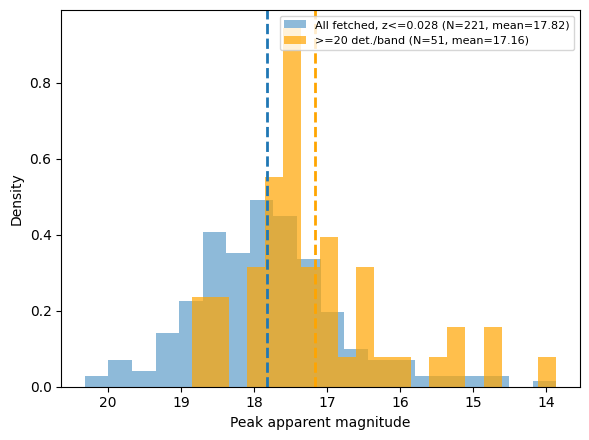

In [ ]:
"""
Our cut of >=20 detections/band ecourages a magnitude-driven selection bias (Fig. 8)
"""
Z_CUT = 0.028  # chosen to shrink the 438-candidate pool to roughly half

cut_all_peak_mags, cut_selected_peaks = [], []
n_total_cut, n_selected_cut, n_dual_cut = 0, 0, 0

for name in tns_ibc["name"]:
    if get_sn_row(name)["redshift"] > Z_CUT:
        continue
    decline_points = get_decline_detections(name, epoch_after_peak=EPOCH_AFTER_PEAK)
    object_all_band_peaks, object_selected_band_peaks = [], []
    bands_ok = 0
    for fid in [1, 2]:
        band_data = [p for p in decline_points if p.get("fid") == fid and "candid" in p]
        if len(band_data) > 0:
            object_all_band_peaks.append(np.min([p["magpsf"] for p in band_data]))
        if len(band_data) < MIN_DETECTIONS_PER_BAND:
            continue
        object_selected_band_peaks.append(np.min([p["magpsf"] for p in band_data]))
        bands_ok += 1
    if object_all_band_peaks:
        cut_all_peak_mags.append(np.min(object_all_band_peaks))
        n_total_cut += 1
    if object_selected_band_peaks:
        cut_selected_peaks.append(np.min(object_selected_band_peaks))
        n_selected_cut += 1
    if bands_ok == 2:
        n_dual_cut += 1

print(f"Redshift cut: z <= {Z_CUT} (vs. the full z <= 0.05 sample)")
print(f"Candidates with a usable light curve: {n_total_cut} "
      f"(was 438 before the cut, {100 * n_total_cut / 438:.0f}% of the original)")
print(f"Candidates satisfying >=20 detections/band: {n_selected_cut} (was 83 before the cut)")
print(f"Dual-band candidates: {n_dual_cut} (was 34 before the cut)")

n_remaining = 0
for name in ["2020sgf", "2022esa", "2022jli"]:
    z = get_sn_row(name)["redshift"]
    survives = z <= Z_CUT
    n_remaining += survives
    print(f"  {name}: z={z:.4f}, survives cut: {survives}")
print(f"Dual-band detections remaining: {n_remaining} out of 3 "
      f"-> {n_remaining} out of {n_dual_cut} dual-band candidates in this sub-sample "
      f"({100 * n_remaining / n_dual_cut:.1f}%, vs. 3/34 = 8.8% in the full sample)")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.hist(cut_all_peak_mags, bins=20, alpha=0.5, density=True, color="C0",
        label=f"All fetched, z<={Z_CUT} (N={n_total_cut}, mean={np.mean(cut_all_peak_mags):.2f})")
ax.hist(cut_selected_peaks, bins=20, alpha=0.7, density=True, color="orange",
        label=f">=20 det./band (N={n_selected_cut}, mean={np.mean(cut_selected_peaks):.2f})")
ax.axvline(np.mean(cut_all_peak_mags), ls="--", lw=2, color="C0")
ax.axvline(np.mean(cut_selected_peaks), ls="--", lw=2, color="orange")
ax.invert_xaxis()
ax.set_xlabel("Peak apparent magnitude")
ax.set_ylabel("Density")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("diagnostics/sample_selection_bias_redshift_cut.pdf", dpi=300, bbox_inches="tight")
plt.show()


## Sawtooth vs. sinusoid injection test (SN 2022jli)


In [5]:
"""Ad-hoc injection-recovery test: does the single-sinusoid model underestimate
the amplitude of an asymmetric (sawtooth-like) periodic signal such as the one
reported for SN 2022jli by Chen et al. (2024)?

A trial counts as a successful period recovery if the recovered period falls
within the same P^2/T tolerance used to define a detection in Sect. 2.4."""
import numpy as np
import pandas as pd

from periodicity_tools import get_decline_detections, analyze_candidate

RNG_SEED = 31415
N_TRIALS = 100
PERIODS = [10, 11, 12, 12.5, 13, 14, 15]  # days, bracketing 2022jli's ~12.4-12.6 d
AMPLITUDES = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20]  # mag, bracketing 2022jli's 0.04/0.07 mag
WAVEFORMS = ["sine", "sawtooth"]
SAWTOOTH_RISE_FRACTION = 0.25  # Chen et al. 2024: fast rise over ~25% of the cycle


def sinusoid(t, period, amplitude, phase):
    return amplitude * np.sin(2 * np.pi * t / period + phase)


def sawtooth(t, period, amplitude, phase, rise_fraction=SAWTOOTH_RISE_FRACTION):
    phase_frac = ((t / period + phase / (2 * np.pi)) % 1.0)
    y = np.empty_like(phase_frac)
    rising = phase_frac < rise_fraction
    y[rising] = -amplitude + 2 * amplitude * (phase_frac[rising] / rise_fraction)
    falling = ~rising
    y[falling] = amplitude - 2 * amplitude * ((phase_frac[falling] - rise_fraction) / (1 - rise_fraction))
    return y


WAVEFORM_FUNCS = {"sine": sinusoid, "sawtooth": sawtooth}


def load_band(name, fid):
    decline_points = get_decline_detections(name, epoch_after_peak=1000)
    band_data = [p for p in decline_points if p.get("fid") == fid and "candid" in p]
    t = np.array([p["jd"] for p in band_data])
    mags = np.array([p["magpsf"] for p in band_data])
    errs = np.array([p["sigmapsf"] for p in band_data])
    days = t - t[0]
    return days, mags, errs


rng = np.random.default_rng(RNG_SEED)
rows = []

for fid, band in [(1, "g"), (2, "r")]:
    days, mags, errs = load_band("2022jli", fid)
    real_fit = analyze_candidate("2022jli", days, mags, errs, poly_deg=3)
    baseline = real_fit["poly_model"](days)
    sigma_eff = np.sqrt(errs ** 2 + 0.015 ** 2)
    print(f"{band}-band: N={len(days)}, real P={real_fit['best_period']:.2f} d, "
          f"real A={real_fit['best_amplitude']:.3f} mag")

    for waveform in WAVEFORMS:
        func = WAVEFORM_FUNCS[waveform]
        for period in PERIODS:
            # Same P^2/T tolerance used to define a dual-band detection in Sect. 2.4.
            period_tol = period ** 2 / real_fit["time_baseline"]
            for amplitude in AMPLITUDES:
                for _ in range(N_TRIALS):
                    phase = rng.uniform(0, 2 * np.pi)
                    signal = func(days, period, amplitude, phase)
                    noise = rng.normal(0, sigma_eff)
                    sim_mags = baseline + signal + noise

                    res = analyze_candidate("2022jli", days, sim_mags, errs, poly_deg=3)

                    rows.append({
                        "band": band,
                        "waveform": waveform,
                        "P_inj": period,
                        "A_inj": amplitude,
                        "P_rec": res["best_period"],
                        "A_rec": res["best_amplitude"],
                        "period_recovered": abs(res["best_period"] - period) < period_tol,
                    })

sawtooth_table = pd.DataFrame(rows)
sawtooth_table.to_csv("diagnostics/sawtooth_injection_test.csv", index=False)

print("\n=== Summary (averaged over all injected P, A, and phase draws) ===")
summary_rows = []
for (band, waveform), sub in sawtooth_table.groupby(["band", "waveform"]):
    # Subtlety: this ratio is only computed on trials where the period was
    # successfully recovered. Lower amplitudes have a lower success rate, so
    # their successful trials are a biased sample, which can make the
    # recovered/injected ratio look closer to 1 than it otherwise would.
    # For an order-of-magnitude estimate, we leave it this way.
    recovered = sub[sub["period_recovered"]]
    amp_ratio = recovered["A_rec"] / recovered["A_inj"]
    summary = {
        "band": band,
        "waveform": waveform,
        "period_recovery_rate": sub["period_recovered"].mean(),
        "mean_amplitude_ratio": amp_ratio.mean(),
        "median_amplitude_ratio": amp_ratio.median(),
        "std_amplitude_ratio": amp_ratio.std(),
    }
    summary_rows.append(summary)
    print(f"{band}-band, {waveform:8s}: period recovered in {summary['period_recovery_rate']*100:5.1f}% "
          f"of trials; recovered/injected amplitude = {summary['mean_amplitude_ratio']:.3f} "
          f"+/- {summary['std_amplitude_ratio']:.3f} (median {summary['median_amplitude_ratio']:.3f})")

pd.DataFrame(summary_rows).to_csv("diagnostics/sawtooth_injection_summary.csv", index=False)


g-band: N=95, real P=12.56 d, real A=0.068 mag


r-band: N=86, real P=12.41 d, real A=0.038 mag



=== Summary (averaged over all injected P, A, and phase draws) ===
g-band, sawtooth: period recovered in  96.7% of trials; recovered/injected amplitude = 0.783 +/- 0.095 (median 0.773)
g-band, sine    : period recovered in  99.6% of trials; recovered/injected amplitude = 1.011 +/- 0.097 (median 1.002)
r-band, sawtooth: period recovered in  97.1% of trials; recovered/injected amplitude = 0.781 +/- 0.095 (median 0.771)
r-band, sine    : period recovered in  99.6% of trials; recovered/injected amplitude = 1.006 +/- 0.094 (median 1.000)


,band,waveform,period_recovery_rate,mean_amplitude_ratio,median_amplitude_ratio,std_amplitude_ratio
0,g,sawtooth,0.967143,0.782503,0.772724,0.095330
1,g,sine,0.995952,1.010715,1.002067,0.097041
2,r,sawtooth,0.970714,0.781485,0.770832,0.095323
3,r,sine,0.995952,1.006146,0.999856,0.093558


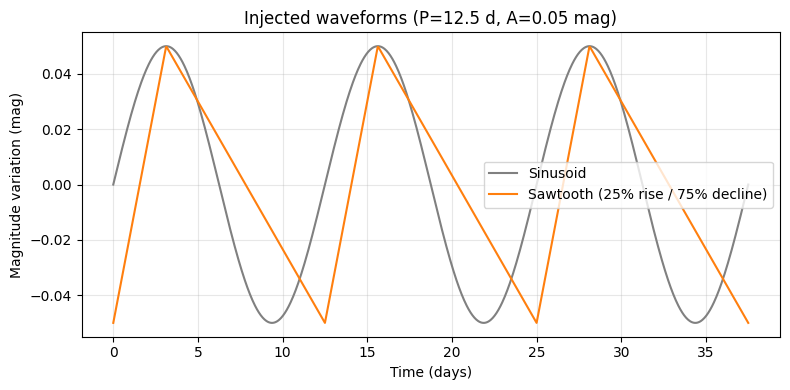

In [6]:
import pandas as pd
summary = pd.read_csv('diagnostics/sawtooth_injection_summary.csv')
display(summary)

# What the injected sawtooth waveform actually looks like, vs. a plain sinusoid
# of the same period and semi-amplitude (Chen et al. 2024's reported profile:
# a fast rise over 25% of the cycle, then a slower decline).
period = 12.5
amplitude = 0.05
t = np.linspace(0, 3 * period, 1000)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, sinusoid(t, period=period, amplitude=amplitude, phase=0), label="Sinusoid", color="0.5")
ax.plot(t, sawtooth(t, period=period, amplitude=amplitude, phase=0), label="Sawtooth (25% rise / 75% decline)", color="C1")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Magnitude variation (mag)")
ax.set_title(f"Injected waveforms (P={period} d, A={amplitude} mag)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Amplitude recovery ratio across the (period, amplitude) grid


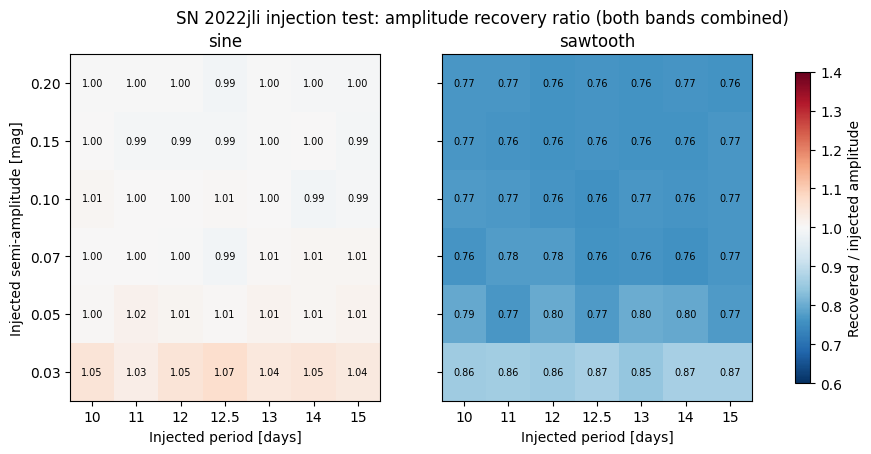

In [7]:
"""Colormap of the recovered/injected amplitude ratio across the injected
(period, amplitude) grid, for the sine and sawtooth injections separately,
averaged over both bands and all phase draws. Shows directly in which part
of the tested parameter space the single-sinusoid model under- or
over-estimates the injected amplitude."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sawtooth_table = pd.read_csv("diagnostics/sawtooth_injection_test.csv")
sawtooth_table["ratio"] = sawtooth_table["A_rec"] / sawtooth_table["A_inj"]
recovered = sawtooth_table[sawtooth_table["period_recovered"]]

periods = sorted(recovered["P_inj"].unique())
amplitudes = sorted(recovered["A_inj"].unique())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, waveform in zip(axes, ["sine", "sawtooth"]):
    sub = recovered[recovered["waveform"] == waveform]
    grid = sub.groupby(["A_inj", "P_inj"])["ratio"].mean().unstack()
    grid = grid.reindex(index=amplitudes, columns=periods)

    im = ax.imshow(
        grid.values, origin="lower", aspect="auto", cmap="RdBu_r", vmin=0.6, vmax=1.4,
        extent=[0, len(periods), 0, len(amplitudes)],
    )
    ax.set_xticks(np.arange(len(periods)) + 0.5)
    ax.set_xticklabels([f"{p:g}" for p in periods])
    ax.set_yticks(np.arange(len(amplitudes)) + 0.5)
    ax.set_yticklabels([f"{a:.2f}" for a in amplitudes])
    ax.set_xlabel("Injected period [days]")
    ax.set_title(f"{waveform}")

    for i, a in enumerate(amplitudes):
        for j, p in enumerate(periods):
            val = grid.values[i, j]
            if np.isfinite(val):
                ax.text(j + 0.5, i + 0.5, f"{val:.2f}", ha="center", va="center", fontsize=7)

axes[0].set_ylabel("Injected semi-amplitude [mag]")
cbar = fig.colorbar(im, ax=axes, shrink=0.9)
cbar.set_label("Recovered / injected amplitude")
plt.suptitle("SN 2022jli injection test: amplitude recovery ratio (both bands combined)")
plt.savefig("diagnostics/sawtooth_amplitude_ratio_colormap.pdf", dpi=200, bbox_inches="tight")
plt.show()


## Sensitivity to polynomial degree

In [ ]:
# Similar to Table 4 - just print the detections for our candidates in different baselines
band_str = {1: "g", 2: "r"}
for name in ["2022jli", "2020sgf", "2022esa"]:
    print(f"=== {name} ===")
    for method in POLY_METHODS:
        for res in grouped_results[method][name]:
            passes = res["p_value_single_freq"] < SINGLE_FREQ_P
            flag = "" if passes else "  <-- FAILS p<1e-4"
            print(f"  {method} {band_str[res['fid']]}: P={res['best_period']:.2f} d, "
                  f"A={res['best_amplitude']:.4f} mag, p={res['p_value_single_freq']:.3e}, "
                  f"dchi2={res['delta_chi2']:.2f}{flag}")
    print(f"  -> dual-band detection under: {[m for m in POLY_METHODS if name in double_hits[m]]}")
    print()

=== 2022jli ===
  poly3 g: P=12.56 d, A=0.0675 mag, p=2.652e-12, dchi2=53.31
  poly3 r: P=12.41 d, A=0.0384 mag, p=4.613e-06, dchi2=24.57
  poly4 g: P=12.56 d, A=0.0694 mag, p=1.588e-13, dchi2=58.94
  poly4 r: P=12.41 d, A=0.0398 mag, p=2.932e-07, dchi2=30.08
  poly5 g: P=12.56 d, A=0.0671 mag, p=2.174e-13, dchi2=58.31
  poly5 r: P=12.41 d, A=0.0397 mag, p=4.029e-07, dchi2=29.45
  poly6 g: P=12.40 d, A=0.0671 mag, p=2.924e-13, dchi2=57.72
  poly6 r: P=12.41 d, A=0.0386 mag, p=2.992e-07, dchi2=30.04
  -> dual-band detection under: ['poly3', 'poly4', 'poly5', 'poly6']

=== 2020sgf ===
  poly3 g: P=30.17 d, A=0.1957 mag, p=6.387e-10, dchi2=42.34
  poly3 r: P=35.94 d, A=0.1140 mag, p=3.014e-09, dchi2=39.24
  poly4 g: P=30.17 d, A=0.1926 mag, p=8.093e-10, dchi2=41.87
  poly4 r: P=64.70 d, A=0.1078 mag, p=3.169e-09, dchi2=39.14
  poly5 g: P=28.94 d, A=0.1540 mag, p=3.894e-06, dchi2=24.91
  poly5 r: P=29.41 d, A=0.0818 mag, p=2.268e-09, dchi2=39.81
  poly6 g: P=28.94 d, A=0.1419 mag, p=2.264e

## Injection-recovery completeness vs. amplitude (saturation check)


In [ ]:
"""
Check how the 0.2 semi-amplitude ceiling affects the recovery
"""
entries_by_name = defaultdict(dict)
for entry in candidate_library:
    if entry["fid"] in (1, 2):
        entries_by_name[entry["name"]][entry["fid"]] = entry

SIG_THRESHOLD = chi2.ppf(1 - SINGLE_FREQ_P, df=2)
P_LO, P_HI = 25, 35
AMPLITUDES = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
N_INJECTIONS = 150
AMP_RNG_SEED = 999


def has_peak_near_period(entry, target_period, period_tol):
    freq, dchi2 = compute_delta_chi2_curve(entry["days"], entry["mags"], entry["errs"], poly_deg=3)
    periods = 1.0 / freq
    mask = np.abs(periods - target_period) < period_tol
    if not np.any(mask):
        return False
    local_dchi2 = dchi2[mask]
    if len(local_dchi2) < 3:
        return np.nanmax(local_dchi2) > SIG_THRESHOLD
    local_max = (local_dchi2[1:-1] > local_dchi2[:-2]) & (local_dchi2[1:-1] > local_dchi2[2:])
    if not np.any(local_max):
        return np.nanmax(local_dchi2) > SIG_THRESHOLD
    return np.any(local_dchi2[1:-1][local_max] > SIG_THRESHOLD)


def recovered_in_both_bands(sim_entries, injected_period):
    results = []
    for entry in sim_entries:
        res = analyze_candidate(entry["name"], entry["days"], entry["mags"], entry["errs"], poly_deg=3)
        res["fid"] = entry["fid"]
        results.append(res)
    r1, r2 = results
    if not (
        r1["p_value_single_freq"] < SINGLE_FREQ_P and r2["p_value_single_freq"] < SINGLE_FREQ_P
        and r1["best_amplitude"] >= r1["mda"] and r2["best_amplitude"] >= r2["mda"]
    ):
        return False
    period_tol = max(r1["best_period"] ** 2 / r1["time_baseline"], r2["best_period"] ** 2 / r2["time_baseline"])
    if not (abs(r1["best_period"] - injected_period) < period_tol or abs(r2["best_period"] - injected_period) < period_tol):
        return False
    return all(has_peak_near_period(entry, injected_period, period_tol) for entry in sim_entries)


def make_injected_light_curve(entry, period, amplitude, rng):
    days, mags = np.asarray(entry["days"]), np.asarray(entry["mags"])
    phase = rng.uniform(0.0, 2.0 * np.pi)
    sim_entry = entry.copy()
    sim_entry["mags"] = mags + amplitude * np.sin(2.0 * np.pi * days / period + phase)
    return sim_entry


eligible_names = [
    name for name in dual_band_names
    if min(entries_by_name[name][1]["days"].max(), entries_by_name[name][2]["days"].max()) / 2.5 >= P_HI
]
print(f"Eligible candidates for P in [{P_LO},{P_HI}]: {len(eligible_names)}/{len(dual_band_names)}")

amp_rng = np.random.default_rng(AMP_RNG_SEED)
amp_rows = []
for amp in AMPLITUDES:
    recovered = 0
    for name in eligible_names:
        for _ in range(N_INJECTIONS):
            injected_period = amp_rng.uniform(P_LO, P_HI)
            sim_entries = [
                make_injected_light_curve(entries_by_name[name][fid], injected_period, amp, amp_rng)
                for fid in (1, 2)
            ]
            recovered += int(recovered_in_both_bands(sim_entries, injected_period))
    total = len(eligible_names) * N_INJECTIONS
    Pij_full_sample = recovered / (len(dual_band_names) * N_INJECTIONS)
    print(f"A={amp:.2f} mag: recovered {recovered}/{total} among eligible "
          f"-> Pij (full-sample normalized) = {Pij_full_sample:.3f}")
    amp_rows.append({"amplitude": amp, "recovered": recovered, "total_trials": total, "Pij_full_sample": Pij_full_sample})

amp_table = pd.DataFrame(amp_rows)
amp_table.to_csv("diagnostics/amplitude_saturation.csv", index=False)
amp_table

Eligible candidates for P in [25,35]: 23/34


A=0.02 mag: recovered 241/3450 among eligible -> Pij (full-sample normalized) = 0.047


A=0.05 mag: recovered 413/3450 among eligible -> Pij (full-sample normalized) = 0.081


A=0.10 mag: recovered 1365/3450 among eligible -> Pij (full-sample normalized) = 0.268


A=0.15 mag: recovered 1689/3450 among eligible -> Pij (full-sample normalized) = 0.331


A=0.20 mag: recovered 2053/3450 among eligible -> Pij (full-sample normalized) = 0.403


A=0.30 mag: recovered 2571/3450 among eligible -> Pij (full-sample normalized) = 0.504


A=0.40 mag: recovered 2684/3450 among eligible -> Pij (full-sample normalized) = 0.526


A=0.50 mag: recovered 2713/3450 among eligible -> Pij (full-sample normalized) = 0.532


,amplitude,recovered,total_trials,Pij_full_sample
0,0.02,241,3450,0.047255
1,0.05,413,3450,0.080980
2,0.10,1365,3450,0.267647
3,0.15,1689,3450,0.331176
4,0.20,2053,3450,0.402549
5,0.30,2571,3450,0.504118
6,0.40,2684,3450,0.526275
7,0.50,2713,3450,0.531961


## Gaussianity of the fit residuals (Shapiro-Wilk test)


In [10]:
"""Tests one of the key assumptions behind the chi-squared significance
calculation (Sect. 2.3): that the baseline-fit residuals, standardized by their
errors, are approximately Gaussian. Run for the three dual-band detections."""
import pandas as pd
from scipy.stats import shapiro

from periodicity_tools import _prepare_baseline

band_str_local = {1: "g", 2: "r"}
shapiro_rows = []
for name in ["2022jli", "2022esa", "2020sgf"]:
    for entry in candidate_library:
        if entry["name"] != name:
            continue
        base = _prepare_baseline(entry["days"], entry["mags"], entry["errs"], poly_deg=3)
        pulls = base["resids"] / base["normalized_errors"]
        stat, p = shapiro(pulls)
        shapiro_rows.append({"SN": name, "band": band_str_local[entry["fid"]], "N": len(pulls), "W": stat, "p_value": p})
        print(f"{name} {band_str_local[entry['fid']]}-band: N={len(pulls)}, Shapiro-Wilk W={stat:.4f}, p={p:.4f}")

shapiro_table = pd.DataFrame(shapiro_rows)
shapiro_table.to_csv("diagnostics/shapiro_wilk_gaussianity.csv", index=False)
shapiro_table


2022jli g-band: N=95, Shapiro-Wilk W=0.9880, p=0.5455
2022jli r-band: N=86, Shapiro-Wilk W=0.9893, p=0.7076
2022esa g-band: N=33, Shapiro-Wilk W=0.9690, p=0.4524
2022esa r-band: N=34, Shapiro-Wilk W=0.9583, p=0.2175
2020sgf g-band: N=82, Shapiro-Wilk W=0.9755, p=0.1177
2020sgf r-band: N=100, Shapiro-Wilk W=0.9645, p=0.0085


,SN,band,N,W,p_value
0,2022jli,g,95,0.987996,0.545521
1,2022jli,r,86,0.989292,0.707583
2,2022esa,g,33,0.968973,0.452380
3,2022esa,r,34,0.958344,0.217487
4,2020sgf,g,82,0.975483,0.117718
5,2020sgf,r,100,0.964490,0.008513


## Toy example: quadratic baseline absorbing part of a sinusoid
Concrete demonstration of the claim made qualitatively in Sect. 2.2 for the illustrative model $y(t) = at^2+bt+c+A\sin(2\pi ft)+B\cos(2\pi ft)$: detrending with a polynomial *before* searching for periodicity can absorb part of the sinusoidal signal, so that "the subsequent period search can underestimate its amplitude or significance." Unlike the cell above, both methods recover the *same, correct* period here -- the effect is specifically on the recovered amplitude and $\Delta\chi^2$, exactly as worded in the text, and $P/T = 2.5$ cycles is chosen to coincide with our own pipeline's search floor (Sect. 2.3).

True period: 40.0 (T/P = 2.50 cycles), true amplitude R = sqrt(A^2+B^2) = 0.158
Joint:      recovered P = 40.03 (+0.1%), R = 0.1605 (+1.5%), dchi2 = 1580.7
Sequential: recovered P = 39.75 (-0.6%), R = 0.1377 (-12.9%), LSP power = 0.8788



40-trial Monte Carlo over random injection phases:
  Joint:      mean P = 39.9 (std 0.3), mean R = 0.1577 (-0.3%), mean dchi2 = 1671.6
  Sequential: mean P = 39.7 (std 0.9), mean R = 0.1411 (-10.8%), mean LSP power = 0.8931


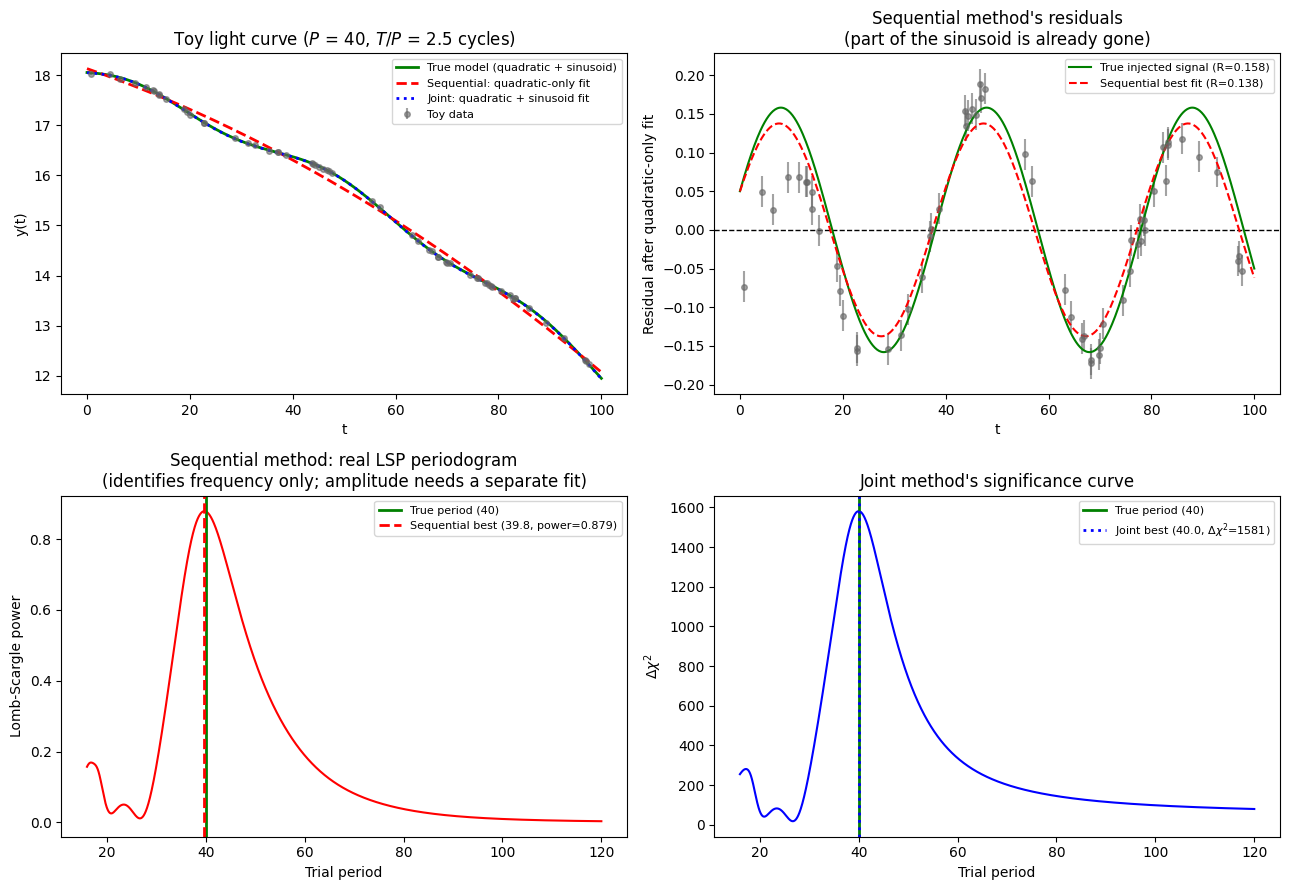

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

rng_global = np.random.default_rng(42)

T = 100.0          # baseline
N = 60             # number of points
P_true = 40.0      # period -> T/P = 2.5 cycles, our own pipeline's floor
A_true, B_true = 0.15, 0.05
R_true = np.hypot(A_true, B_true)
sigma = 0.02
# a modest, realistic declining-light-curve trend -- the degeneracy below does
# not depend on this choice (a flat baseline, a=b=c=0, gives the same result)
a_true, b_true, c_true = -0.0003, -0.03, 18.0

t = np.sort(rng_global.uniform(0, T, N))
trend = a_true * t**2 + b_true * t + c_true
signal = A_true * np.sin(2*np.pi*t/P_true) + B_true * np.cos(2*np.pi*t/P_true)
y = trend + signal + rng_global.normal(0, sigma, N)
err = np.full(N, sigma)
w = 1 / err


def quad_design(tt):
    return np.column_stack([np.ones_like(tt), tt, tt**2])


period_grid = np.linspace(16, 120, 3000)
freq_grid = 1 / period_grid

# --- Sequential: fit quadratic ALONE, then search the residuals with a real
#     Lomb-Scargle periodogram (same tool used for the real SN~2020sgf
#     comparison above). LSP gives us the best-fit frequency/period directly;
#     amplitude is recovered as a separate follow-up sin+cos fit at that
#     frequency (see module docstring). ---
Xq = quad_design(t)
poly_coeffs, *_ = np.linalg.lstsq(Xq * w[:, None], y * w, rcond=None)
poly_only_fit = Xq @ poly_coeffs
resid = y - poly_only_fit

seq_power_curve = LombScargle(t, resid, err).power(freq_grid)
seq_best = np.argmax(seq_power_curve)
seq_P, seq_power = period_grid[seq_best], seq_power_curve[seq_best]

# amplitude at the LSP-identified best frequency (lstsq sin+cos fit to residuals)
om_seq = 2*np.pi/seq_P
X_seq = np.column_stack([np.sin(om_seq*t), np.cos(om_seq*t)])
seq_coeffs, *_ = np.linalg.lstsq(X_seq * w[:, None], resid * w, rcond=None)
seq_R = np.hypot(*seq_coeffs)

# --- Joint: fit quadratic + sin + cos together at each trial frequency ---
chi2_poly = np.sum(((y - Xq @ poly_coeffs) / err)**2)
joint_dchi2_curve = np.empty(len(freq_grid))
joint_coeffs_grid = []
for i, f in enumerate(freq_grid):
    om = 2*np.pi*f
    X = np.column_stack([Xq, np.sin(om*t), np.cos(om*t)])
    c, *_ = np.linalg.lstsq(X * w[:, None], y * w, rcond=None)
    joint_dchi2_curve[i] = chi2_poly - np.sum(((y - X @ c) / err)**2)
    joint_coeffs_grid.append(c)
joint_best = np.argmax(joint_dchi2_curve)
joint_P, joint_coeffs_full, joint_dchi2 = period_grid[joint_best], joint_coeffs_grid[joint_best], joint_dchi2_curve[joint_best]
joint_R = np.hypot(*joint_coeffs_full[3:5])

print(f"True period: {P_true:.1f} (T/P = {T/P_true:.2f} cycles), true amplitude R = sqrt(A^2+B^2) = {R_true:.3f}")
print(f"Joint:      recovered P = {joint_P:.2f} ({100*(joint_P-P_true)/P_true:+.1f}%), "
      f"R = {joint_R:.4f} ({100*(joint_R-R_true)/R_true:+.1f}%), dchi2 = {joint_dchi2:.1f}")
print(f"Sequential: recovered P = {seq_P:.2f} ({100*(seq_P-P_true)/P_true:+.1f}%), "
      f"R = {seq_R:.4f} ({100*(seq_R-R_true)/R_true:+.1f}%), LSP power = {seq_power:.4f}")

# --- Monte Carlo over 40 random injection phases, to show this isn't a cherry-picked draw ---
# We only compare AMPLITUDE between the two methods (same units, same definition
# in both cases: a direct sin+cos fit at each method's own best-fit frequency).
# We deliberately do not try to compare joint's Delta-chi^2 to sequential's LSP
# power against each other -- they are different statistics on different scales.
def run_trial(phase, seed):
    rng = np.random.default_rng(seed)
    tt = np.sort(rng.uniform(0, T, N))
    A, B = R_true*np.cos(phase), R_true*np.sin(phase)
    yy = (a_true*tt**2 + b_true*tt + c_true + A*np.sin(2*np.pi*tt/P_true)
          + B*np.cos(2*np.pi*tt/P_true) + rng.normal(0, sigma, N))
    ww = 1/err

    # sequential: quadratic-only fit, then real LSP on the residuals for the
    # best-fit frequency, then a sin+cos fit at that frequency for amplitude
    Xqq = quad_design(tt)
    cp, *_ = np.linalg.lstsq(Xqq*ww[:,None], yy*ww, rcond=None)
    rr = yy - Xqq@cp
    seq_power_grid = LombScargle(tt, rr, err).power(freq_grid)
    i_s = np.argmax(seq_power_grid)
    seq_f, seq_pow = freq_grid[i_s], seq_power_grid[i_s]
    om_s = 2*np.pi*seq_f
    X_s = np.column_stack([np.sin(om_s*tt), np.cos(om_s*tt)])
    c_s, *_ = np.linalg.lstsq(X_s*ww[:,None], rr*ww, rcond=None)

    # joint: quadratic + sin + cos fit together, Delta-chi^2 for significance
    c2poly = np.sum(((yy - Xqq@cp)/err)**2)
    best_j = None
    for f in freq_grid:
        om = 2*np.pi*f
        X = np.column_stack([Xqq, np.sin(om*tt), np.cos(om*tt)])
        c, *_ = np.linalg.lstsq(X*ww[:,None], yy*ww, rcond=None)
        d = c2poly - np.sum(((yy - X@c)/err)**2)
        if best_j is None or d > best_j[0]:
            best_j = (d, f, c[3:5])

    return (1/seq_f, np.hypot(*c_s), seq_pow, 1/best_j[1], np.hypot(*best_j[2]), best_j[0])

n_mc = 40
mc = np.array([run_trial(np.random.default_rng(1000+i).uniform(0, 2*np.pi), 2000+i) for i in range(n_mc)])
seq_P_mc, seq_R_mc, seq_pow_mc = mc[:,0], mc[:,1], mc[:,2]
joint_P_mc, joint_R_mc, joint_dchi2_mc = mc[:,3], mc[:,4], mc[:,5]
print(f"\n{n_mc}-trial Monte Carlo over random injection phases:")
print(f"  Joint:      mean P = {joint_P_mc.mean():.1f} (std {joint_P_mc.std():.1f}), "
      f"mean R = {joint_R_mc.mean():.4f} ({100*(joint_R_mc.mean()-R_true)/R_true:+.1f}%), mean dchi2 = {joint_dchi2_mc.mean():.1f}")
print(f"  Sequential: mean P = {seq_P_mc.mean():.1f} (std {seq_P_mc.std():.1f}), "
      f"mean R = {seq_R_mc.mean():.4f} ({100*(seq_R_mc.mean()-R_true)/R_true:+.1f}%), mean LSP power = {seq_pow_mc.mean():.4f}")

# --- Plots ---
t_grid_plot = np.linspace(0, T, 500)
true_model_plot = (a_true*t_grid_plot**2 + b_true*t_grid_plot + c_true
                    + A_true*np.sin(2*np.pi*t_grid_plot/P_true) + B_true*np.cos(2*np.pi*t_grid_plot/P_true))
poly_only_plot = quad_design(t_grid_plot) @ poly_coeffs
om_joint = 2*np.pi/joint_P
joint_full_plot = quad_design(t_grid_plot) @ joint_coeffs_full[:3] \
    + joint_coeffs_full[3]*np.sin(om_joint*t_grid_plot) + joint_coeffs_full[4]*np.cos(om_joint*t_grid_plot)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0, 0]
ax.errorbar(t, y, yerr=err, fmt="o", ms=4, color="0.4", alpha=0.6, label="Toy data")
ax.plot(t_grid_plot, true_model_plot, color="green", lw=2, label="True model (quadratic + sinusoid)")
ax.plot(t_grid_plot, poly_only_plot, color="red", lw=2, ls="--", label="Sequential: quadratic-only fit")
ax.plot(t_grid_plot, joint_full_plot, color="blue", lw=2, ls=":", label="Joint: quadratic + sinusoid fit")
ax.set_xlabel("t")
ax.set_ylabel("y(t)")
ax.set_title(f"Toy light curve ($P$ = {P_true:.0f}, $T/P$ = {T/P_true:.1f} cycles)")
ax.legend(fontsize=8)

ax = axes[0, 1]
ax.errorbar(t, resid, yerr=err, fmt="o", ms=4, color="0.4", alpha=0.6)
ax.axhline(0, color="k", ls="--", lw=1)
tt_plot = np.linspace(0, T, 500)
ax.plot(tt_plot, A_true*np.sin(2*np.pi*tt_plot/P_true) + B_true*np.cos(2*np.pi*tt_plot/P_true),
        color="green", lw=1.5, label=f"True injected signal (R={R_true:.3f})")
seq_om = 2*np.pi/seq_P
ax.plot(tt_plot, seq_coeffs[0]*np.sin(seq_om*tt_plot) + seq_coeffs[1]*np.cos(seq_om*tt_plot),
        color="red", lw=1.5, ls="--", label=f"Sequential best fit (R={seq_R:.3f})")
ax.set_xlabel("t")
ax.set_ylabel("Residual after quadratic-only fit")
ax.set_title("Sequential method's residuals\n(part of the sinusoid is already gone)")
ax.legend(fontsize=8)

ax = axes[1, 0]
ax.plot(period_grid, seq_power_curve, color="red", lw=1.5)
ax.axvline(P_true, color="green", ls="-", lw=2, label=f"True period ({P_true:.0f})")
ax.axvline(seq_P, color="red", ls="--", lw=2, label=f"Sequential best ({seq_P:.1f}, power={seq_power:.3f})")
ax.set_xlabel("Trial period")
ax.set_ylabel("Lomb-Scargle power")
ax.set_title("Sequential method: real LSP periodogram\n(identifies frequency only; amplitude needs a separate fit)")
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.plot(period_grid, joint_dchi2_curve, color="blue", lw=1.5)
ax.axvline(P_true, color="green", ls="-", lw=2, label=f"True period ({P_true:.0f})")
ax.axvline(joint_P, color="blue", ls=":", lw=2, label=f"Joint best ({joint_P:.1f}, $\\Delta\\chi^2$={joint_dchi2:.0f})")
ax.set_xlabel("Trial period")
ax.set_ylabel(r"$\Delta\chi^2$")
ax.set_title("Joint method's significance curve")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("diagnostics/quadratic_degeneracy_example.pdf", dpi=150, bbox_inches="tight")
plt.show()
